In [1]:
import matplotlib.pyplot as pp
import numpy as np
import itertools as it
import pulp as pulp

def display_thermometersudoku( dica, sol = None, thermometers = None, savefig = False, namefile = 'default.png' ):
    pp.figure( figsize = ( 8, 8 ) )
    ax = pp.gca()

    L = int( np.round( dica.shape[ 0 ] ** 0.5 ) )

    ax.set_xticks( np.arange( 0, L ** 2 + 1, 1 ), minor = True )
    ax.set_yticks( np.arange( 0, L ** 2 + 1, 1 ), minor = True )
    ax.grid(which = 'minor')
    ax.set_xticks( np.arange( 0, L ** 2 + 1, L ), [] * L, minor = False )
    ax.set_yticks( np.arange( 0, L ** 2 + 1, L ), [] * L, minor = False )
    ax.grid( which = 'major', linewidth = 2, color = 'k' )

    # Dicas (em vermelho)
    for i in range( L ** 2 ):
        for j in range( L ** 2 ):
            if dica[ i, j ] != 0:
                pp.text(
                    j + 0.5, L ** 2 - i - 0.5,
                    str( dica[ i, j ] ),
                    ha = 'center', va = 'center',
                    fontsize = 20, color = 'black'
                )

    # Solução (em preto)
    if sol is not None:
        for i in range( L ** 2 ):
            for j in range( L ** 2 ):
                if dica[ i, j ] == 0:
                    pp.text(
                        j + 0.5, L ** 2 - i - 0.5,
                        str( sol[ i, j ] ),
                        ha = 'center', va = 'center',
                        fontsize = 20
                    )

    # Desenha termômetros
    if thermometers is not None:
        bulb_radius = 0.40
        stem_width = 0.25
        color = 'gray'

        for thermo in thermometers:
            # Desenhar o bulbo (primeira célula)
            i0, j0 = thermo[ 0 ]
            x0 = j0 + 0.5
            y0 = L ** 2 - i0 - 0.5
            circ = pp.Circle( ( x0, y0 ), bulb_radius, color = color, zorder = 1 )
            ax.add_patch( circ )

            # Desenhar os "tubos" entre os centros das células
            for (i1, j1), (i2, j2) in zip( thermo, thermo[ 1 : ] ):
                x1, y1 = j1 + 0.5, L ** 2 - i1 - 0.5
                x2, y2 = j2 + 0.5, L ** 2 - i2 - 0.5
                ax.plot( [ x1, x2 ], [ y1, y2 ], color = color, linewidth = stem_width * 100, solid_capstyle = 'round', zorder = 0 )

    pp.xlim( 0, L ** 2 )
    pp.ylim( 0, L ** 2 )
    ax.set_aspect( 'equal' )
    if savefig:
        pp.savefig( namefile, bbox_inches = 'tight', dpi = 300 )
    pp.show()

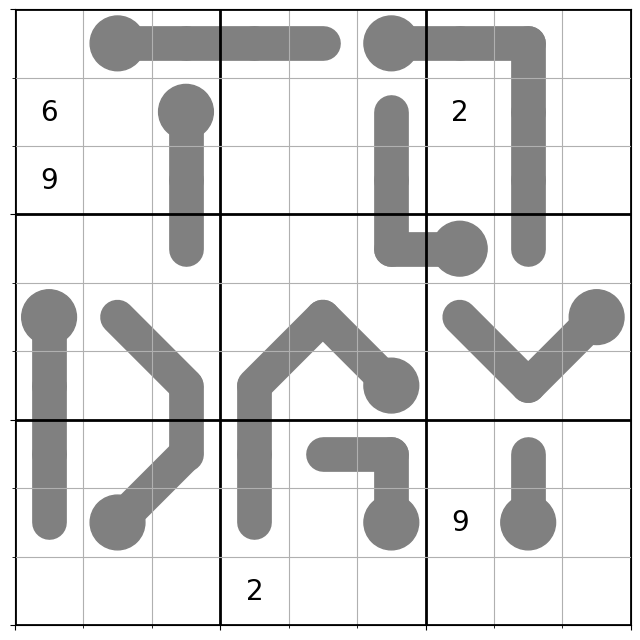

In [2]:
# Instância do problema ( Com dicas e todos os termômetros configurados abaixo )
thermometers = [[(0, 1), (0, 2), (0, 3), (0, 4)],
 [(0, 5), (0, 6), (0, 7), (1, 7), (2, 7), (3, 7)],
 [(1, 2), (2, 2), (3, 2)],
 [(3, 6), (3, 5), (2, 5), (1, 5)],
 [(4, 0), (5, 0), (6, 0), (7, 0)],
 [(4, 8), (5, 7), (4, 6)],
 [(5, 5), (4, 4), (5, 3), (6, 3), (7, 3)],
 [(7, 1), (6, 2), (5, 2), (4, 1)],
 [(7, 5), (6, 5), (6, 4)],
 [(7, 7), (6, 7)]]

dica = np.array([
    [ 0, 0, 0, 0, 0, 0, 0, 0, 0 ],
    [ 6, 0, 0, 0, 0, 0, 2, 0, 0 ],
    [ 9, 0, 0, 0, 0, 0, 0, 0, 0 ],
    [ 0, 0, 0, 0, 0, 0, 0, 0, 0 ],
    [ 0, 0, 0, 0, 0, 0, 0, 0, 0 ],
    [ 0, 0, 0, 0, 0, 0, 0, 0, 0 ],
    [ 0, 0, 0, 0, 0, 0, 0, 0, 0 ],
    [ 0, 0, 0, 0, 0, 0, 9, 0, 0 ],
    [ 0, 0, 0, 2, 0, 0, 0, 0, 0 ]
])

display_thermometersudoku( dica = dica , sol=None, thermometers = thermometers, savefig = True, namefile = 'thermometersudoku.png' )

In [5]:
# Dimensão do Sudoku
L = 3

# Criando Variáveis do problema
x={}
for i, j, k in it.product( range( L ** 2 ), repeat = 3 ):
    x[ i, j, k ] = pulp.LpVariable( 
        name = f'x_{ i + 1 },{ j + 1 },{ k + 1 }',
        cat = pulp.LpBinary
    )

# Criando o modelo
p = pulp.LpProblem( 'KillerSudoku' )

# Todo quadrado contém apenas um número
for i, j in it.product( range( L ** 2 ), repeat = 2 ):
    p += pulp.lpSum( x[ i, j, k ] for k in range( L ** 2 ) ) == 1 

# Toda linha contém apenas uma ocorrência de cada número
for i, k in it.product( range( L ** 2 ), repeat = 2 ):
    p += pulp.lpSum( x[ i, j, k ] for j in range( L ** 2 ) ) == 1

# Toda coluna contém apenas uma ocorrência de cada número
for j, k in it.product( range( L ** 2 ), repeat = 2 ):
    p += pulp.lpSum( x[ i , j, k ] for i in range( L ** 2 ) ) == 1

# Todo subquadrado L x L contém apenas uma ocorrência de cada número
for I, J, k in it.product( range( L ), range( L ), range( L ** 2 ) ):
    p += pulp.lpSum( 
        x[ I * L + i, J * L + j, k ] for i, j in it.product( range( L ), repeat = 2 )
    ) == 1

# Todo termômetro tem os números seguindo ordem crescente
for thermo in thermometers:
    for ( i1, j1 ), ( i2, j2 ) in zip( thermo, thermo[ 1 : ] ):
        p += pulp.lpSum( ( k + 1 ) * x[ i1, j1, k ] for k in range( L ** 2 ) ) + 1 <= \
             pulp.lpSum( ( k + 1 ) * x[ i2, j2, k ] for k in range( L ** 2 ) )

# Aplicar as dicas na solução inicial
for i, j in it.product( range( L ** 2 ), repeat = 2 ):
    if dica[ i, j ] != 0:
        p += ( x[ i, j, dica[ i, j ] - 1 ] == 1 )

"""
Está sendo usado o solver GUROBI aqui, mas você pode trocar para outro solver caso não tenha uma licença 
para usá-lo ou pode adquirí-la em:

https://www.gurobi.com/academia/academic-program-and-licenses/
"""
# Verifique a licença
p.solve(
    pulp.GUROBI( msg = False )
)

print( pulp.LpStatus[ p.status ] )

Optimal


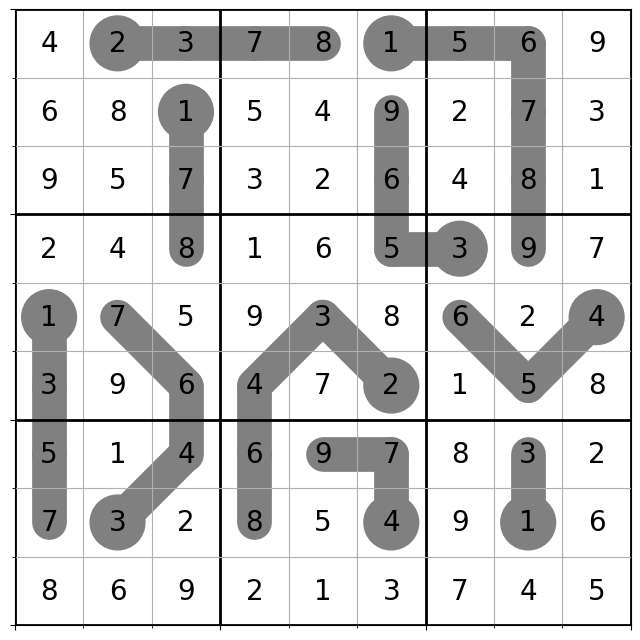

In [4]:
solution = np.empty( ( L ** 2, L ** 2 ), dtype = int )
for i, j, k in it.product( range( L ** 2 ), repeat = 3 ):
    if x[ i, j, k ].value() > 1e-6:
        solution[ i, j ] = k + 1


display_thermometersudoku( dica = dica, sol = solution, thermometers = thermometers, savefig = True, namefile = 'solution_thermometersudoku.png'  )